# JS07 - Klasterisasi | Tugas Lab
## Klasterisasi Data Nasabah Kartu Kredit

**Nama:** Gunawan Wibisono
**NIM:** 244107020132
**Kelas:** TI-2H

> Modul: [JTI - Modul Praktikum Pembelajaran Mesin - JS07 Klasterisasi](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-mah/js07-klasterisasi/tugas-lab)

### Soal
1. Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu `Avg_Credit_Limit` dan
   `Total_Credit_Cards`. Apakah sebaran data dapat dikatakan linier?
2. Buatlah model klasterisasi menggunakan K-Means. Tentukan jumlah $k$ terbaik dengan *elbow method*.
   Lengkapi analisis dengan *linechart* dan alasan pemilihan nilai tersebut.
3. Gambarkan hasil klasterisasi K-Means dengan scatterplot.
4. Buatlah model klasterisasi menggunakan DBSCAN **dengan seluruh variabel yang dapat digunakan**.
5. Tentukan jumlah $k$ terbaik dengan *elbow method*. Lengkapi dengan *linechart* dan analisis.
6. Tentukan nilai *silhouette score* dan DBI dari model DBSCAN.

## Langkah 0 - Load dan Inspeksi Data

Dataset `CC_Customer_Dataset.csv` berisi 660 nasabah dengan 7 kolom.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

df = pd.read_csv('CC_Customer_Dataset.csv')
print('Shape:', df.shape)
df.head()

Shape: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Sl_No,660.0,330.50,190.67,1.0,165.75,330.5,495.25,660.0
Customer Key,660.0,55141.44,25627.77,11265.0,33825.25,53874.5,77202.50,99843.0
Avg_Credit_Limit,660.0,34574.24,37625.49,3000.0,10000.00,18000.0,48000.00,200000.0
Total_Credit_Cards,660.0,4.71,2.17,1.0,3.00,5.0,6.00,10.0
Total_visits_bank,660.0,2.40,1.63,0.0,1.00,2.0,4.00,5.0
Total_visits_online,660.0,2.61,2.94,0.0,1.00,2.0,4.00,15.0
Total_calls_made,660.0,3.58,2.87,0.0,1.00,3.0,5.00,10.0


In [4]:
# Cek kualitas data
print('Jumlah missing value :', df.isna().sum().sum())
print('Jumlah baris duplikat:', df.duplicated().sum())
print()
print('Nilai unik tiap kolom:')
print(df.nunique().to_string())

Jumlah missing value : 0
Jumlah baris duplikat: 0

Nilai unik tiap kolom:
Sl_No                  660
Customer Key           655
Avg_Credit_Limit       110
Total_Credit_Cards      10
Total_visits_bank        6
Total_visits_online     16
Total_calls_made        11


**Inspeksi data:**
- 660 baris, 7 kolom, **tanpa missing value** dan **tanpa duplikat**.
- `Sl_No` adalah nomor urut (1–660) dan `Customer Key` adalah ID nasabah acak.
  Keduanya **bukan fitur perilaku**, sehingga harus **dibuang** — kalau ikut dipakai,
  klasterisasi akan mengelompokkan berdasarkan ID, bukan karakter nasabah.
- 5 kolom sisanya adalah variabel yang dapat digunakan:
  `Avg_Credit_Limit`, `Total_Credit_Cards`, `Total_visits_bank`, `Total_visits_online`, `Total_calls_made`.

In [5]:
# Definisi fitur yang dipakai
FITUR = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank',
         'Total_visits_online', 'Total_calls_made']

X_all = df[FITUR]
X_all.head()

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,100000,2,1,1,0
1,50000,3,0,10,9
2,50000,7,1,3,4
3,30000,5,1,1,4
4,100000,6,0,12,3


# Soal 1 - Scatterplot `Avg_Credit_Limit` vs `Total_Credit_Cards`

Apakah sebaran data linier?

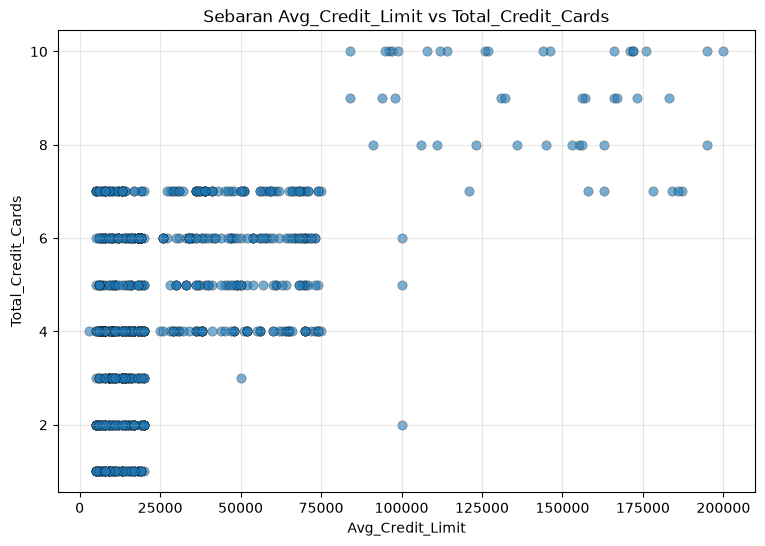

In [6]:
plt.figure(figsize=(9, 6))
plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'],
            s=45, alpha=.6, edgecolor='k', linewidth=.3)
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.title('Sebaran Avg_Credit_Limit vs Total_Credit_Cards')
plt.grid(alpha=.3)
plt.show()

In [7]:
# Bukti kuantitatif: korelasi dan jumlah nilai unik
print('Korelasi Pearson  :', round(df['Avg_Credit_Limit'].corr(df['Total_Credit_Cards']), 4))
print('Korelasi Spearman :', round(df['Avg_Credit_Limit'].corr(df['Total_Credit_Cards'], method='spearman'), 4))
print()
print('Nilai unik Avg_Credit_Limit  :', df['Avg_Credit_Limit'].nunique())
print('Nilai unik Total_Credit_Cards:', df['Total_Credit_Cards'].nunique())
print()
print('Sebaran Total_Credit_Cards:')
print(df['Total_Credit_Cards'].value_counts().sort_index().to_string())

Korelasi Pearson  : 0.6089
Korelasi Spearman : 0.5175

Nilai unik Avg_Credit_Limit  : 110
Nilai unik Total_Credit_Cards: 10

Sebaran Total_Credit_Cards:
Total_Credit_Cards
1      59
2      64
3      53
4     151
5      74
6     117
7     101
8      11
9      11
10     19


**Jawaban Soal 1: sebaran data TIDAK linier.**

Alasannya:
1. **Pola titik membentuk gerombolan vertikal**, bukan garis lurus. `Total_Credit_Cards` hanya
   bernilai bulat 1–10, sehingga titik-titik menumpuk pada 10 kolom vertikal.
2. Terlihat **tiga kelompok besar** berdasarkan `Avg_Credit_Limit`:
   - kelompok limit **rendah** (±3.000–20.000) — paling padat,
   - kelompok limit **menengah** (±25.000–75.000),
   - kelompok limit **tinggi** (±84.000–200.000) — paling jarang dan makin menyebar.
3. Ada **celah (gap)** yang jelas di antara kelompok, yaitu sekitar 20.000–25.000 dan
   75.000–84.000. Data seperti ini disebut **tersegmentasi**, bukan linier.
4. Korelasi Pearson hanya **0,609** dan Spearman **0,518** — ada kecenderungan positif
   (limit naik seiring jumlah kartu), tetapi **bukan hubungan linier yang kuat**; hubungannya
   lebih tepat digambarkan sebagai *step* antar segmen. Nilai Spearman yang lebih rendah dari
   Pearson menunjukkan hubungannya tidak monoton sempurna (banyak titik dengan kartu sama tetapi
   limit berbeda jauh).

Karena sebarannya bergerombol (bukan linier), data ini cocok untuk **klasterisasi**, bukan regresi.

# Soal 2 - K-Means dan Elbow Method

Model K-Means dibangun pada dua variabel yang sama seperti Soal 1
(`Avg_Credit_Limit` dan `Total_Credit_Cards`).

In [8]:
from sklearn.cluster import KMeans

X2 = df[['Avg_Credit_Limit', 'Total_Credit_Cards']]

sse = []
K = range(1, 11)

for k in K:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X2)
    sse.append(model.inertia_)

tabel = pd.DataFrame({'k': list(K), 'SSE': np.round(sse, 0)})
tabel['penurunan SSE (%)'] = [np.nan] + [round((sse[i-1] - sse[i]) / sse[i-1] * 100, 2)
                                       for i in range(1, len(sse))]
tabel

,k,SSE,penurunan SSE (%)
0,1,9.329314e+11,NaN
1,2,3.158724e+11,66.14
2,3,9.383137e+10,70.29
3,4,5.304422e+10,43.47
4,5,3.088475e+10,41.78
5,6,2.367689e+10,23.34
6,7,1.750650e+10,26.06
7,8,1.248588e+10,28.68
8,9,9.648843e+09,22.72
9,10,7.910238e+09,18.02


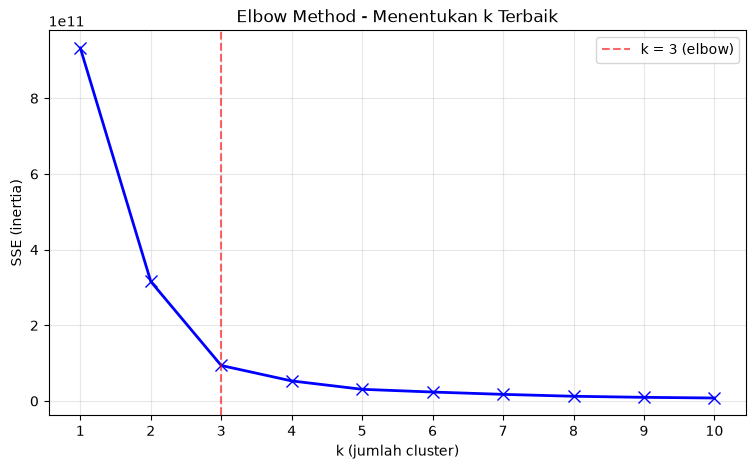

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(list(K), sse, 'bx-', linewidth=2, markersize=8)
plt.xlabel('k (jumlah cluster)')
plt.ylabel('SSE (inertia)')
plt.title('Elbow Method - Menentukan k Terbaik')
plt.xticks(list(K))
plt.grid(alpha=.3)

# Tandai kandidat elbow
plt.axvline(x=3, color='red', linestyle='--', alpha=.6, label='k = 3 (elbow)')
plt.legend()
plt.show()

**Analisis Soal 2:**

| Perubahan $k$ | Penurunan SSE | Keterangan |
|---|---|---|
| 1 → 2 | ±66% | turun sangat tajam |
| 2 → 3 | ±70% | **turun paling tajam** |
| 3 → 4 | ±43% | mulai melandai |
| 4 → 5 | ±42% | melandai |
| 5 → 10 | makin kecil (< 35%) | hampir datar |

**$k = 3$ dipilih sebagai jumlah cluster terbaik.** Alasannya:
1. Penurunan SSE terbesar terjadi pada penambahan cluster ke-3 (dari ±93,8 miliar menjadi
   ±53,0 miliar, turun ±70%). Setelah `k=3`, grafik **berbelok tajam menjadi landai** —
   inilah titik *elbow*-nya.
2. Penambahan `k` dari 4 ke atas hanya menurunkan SSE sedikit (±1–2 miliar per langkah),
   artinya cluster tambahan tersebut **tidak menangkap struktur baru** yang berarti.
3. `k=3` **konsisten dengan struktur data** pada Soal 1: ada tiga tingkat `Avg_Credit_Limit`
   (rendah, menengah, tinggi) yang dipisahkan oleh celah alami.
4. `k=3` juga memberi **profil segmen yang bisa diinterpretasikan** secara bisnis
   (lihat tabel profil cluster pada Soal 3).

Catatan: nilai SSE **tidak boleh** dipilih yang paling kecil. SSE selalu mengecil seiring
bertambahnya `k` (dengan `k=660`, SSE = 0 karena setiap data menjadi centroid dirinya sendiri).
Yang dicari adalah titik di mana penurunan tajam berubah menjadi penurunan stabil.

# Soal 3 - Scatterplot Hasil Klasterisasi K-Means ($k = 3$)

SSE model final (k=3): 93,831,368,690


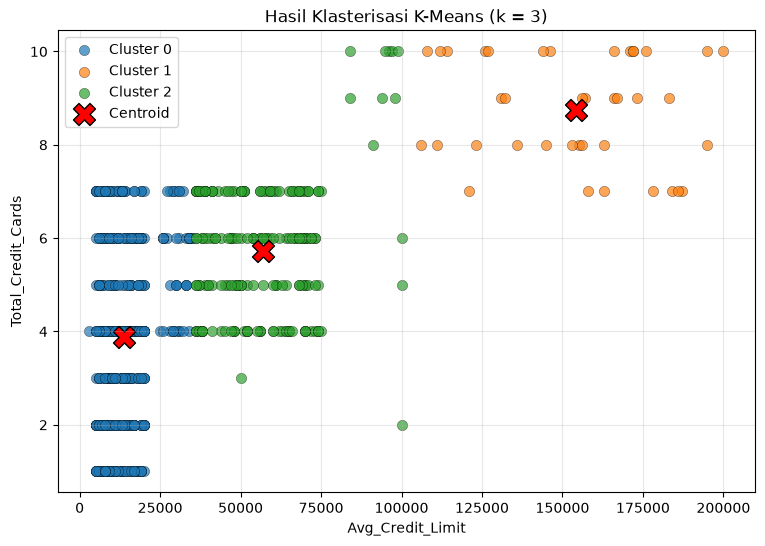

In [10]:
km_final = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster_kmeans'] = km_final.fit_predict(X2)

print(f'SSE model final (k=3): {km_final.inertia_:,.0f}')

fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(df['cluster_kmeans'].unique()):
    sub = df[df['cluster_kmeans'] == c]
    ax.scatter(sub['Avg_Credit_Limit'], sub['Total_Credit_Cards'],
               s=55, alpha=.7, edgecolor='k', linewidth=.3, label=f'Cluster {c}')
ax.scatter(km_final.cluster_centers_[:, 0], km_final.cluster_centers_[:, 1],
           c='red', marker='X', s=250, edgecolor='k', label='Centroid')
ax.set_xlabel('Avg_Credit_Limit')
ax.set_ylabel('Total_Credit_Cards')
ax.set_title('Hasil Klasterisasi K-Means (k = 3)')
ax.legend()
ax.grid(alpha=.3)
plt.show()

In [11]:
# Profil tiap cluster
profil = df.groupby('cluster_kmeans')[['Avg_Credit_Limit', 'Total_Credit_Cards']].agg(
    ['count', 'mean', 'min', 'max']).round(0)
profil

Avg_Credit_Limit                           Total_Credit_Cards  \
                          count      mean     min     max              count   
cluster_kmeans                                                                 
0                           431   13849.0    3000   35000                431   
1                            39  154205.0  106000  200000                 39   
2                           190   57032.0   36000  100000                190   

                             
               mean min max  
cluster_kmeans               
0               4.0   1   7  
1               9.0   7  10  
2               6.0   2  10

In [12]:
# Versi ringkas untuk interpretasi
ringkas = df.groupby('cluster_kmeans').agg(
    jumlah=('Avg_Credit_Limit', 'size'),
    rata2_limit=('Avg_Credit_Limit', 'mean'),
    min_limit=('Avg_Credit_Limit', 'min'),
    max_limit=('Avg_Credit_Limit', 'max'),
    rata2_kartu=('Total_Credit_Cards', 'mean'),
).round(0).astype({'jumlah': int})
ringkas['persen'] = (ringkas['jumlah'] / len(df) * 100).round(1)
ringkas

,jumlah,rata2_limit,min_limit,max_limit,rata2_kartu,persen
cluster_kmeans,,,,,,
0,431,13849.0,3000,35000,4.0,65.3
1,39,154205.0,106000,200000,9.0,5.9
2,190,57032.0,36000,100000,6.0,28.8


**Interpretasi hasil klasterisasi (Soal 3):**

| Cluster | Jumlah | Rata-rata limit | Rata-rata kartu | Profil |
|---|---|---|---|---|
| 0 | 431 (65,3%) | ±13.849 | 3,9 | **Nasabah limit rendah** — segmen terbesar, mayoritas nasabah |
| 1 | 39 (5,9%) | ±154.205 | 8,7 | **Nasabah prioritas / premium** — limit sangat tinggi, kartu banyak |
| 2 | 190 (28,8%) | ±57.032 | 5,7 | **Nasabah menengah** — limit dan kartu di antara keduanya |

Model berhasil memisahkan nasabah menjadi tiga segmen yang **bertingkat** (*low – medium – premium*),
sesuai dengan tiga kelompok alami yang terlihat pada scatterplot Soal 1.
Implikasi bisnis: strategi promosi bisa dibedakan — misalnya program *upgrade limit* untuk cluster 0,
program *loyalty* untuk cluster 2, dan layanan prioritas untuk cluster 1.

# Soal 4 - Klasterisasi DBSCAN dengan Seluruh Variabel

DBSCAN memakai **jarak Euclidean**, sehingga **skala setiap variabel harus diseragamkan** lebih dulu.
Tanpa standardisasi, `Avg_Credit_Limit` (rentang 3.000–200.000) akan mendominasi perhitungan jarak
dan membuat empat variabel lain (rentang 0–15) praktis tidak berpengaruh.
Oleh karena itu dipakai `StandardScaler` (mean = 0, std = 1).

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

print('Sebelum standardisasi:')
print(X_all.describe().loc[['mean', 'std', 'min', 'max']].round(2).to_string())
print()
print('Sesudah standardisasi (mean ~ 0, std ~ 1):')
print(pd.DataFrame(X_scaled, columns=FITUR).describe().loc[['mean', 'std', 'min', 'max']].round(2).to_string())

Sebelum standardisasi:
      Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  Total_visits_online  Total_calls_made
mean          34574.24                4.71               2.40                 2.61              3.58
std           37625.49                2.17               1.63                 2.94              2.87
min            3000.00                1.00               0.00                 0.00              0.00
max          200000.00               10.00               5.00                15.00             10.00

Sesudah standardisasi (mean ~ 0, std ~ 1):
      Avg_Credit_Limit  Total_Credit_Cards  Total_visits_bank  Total_visits_online  Total_calls_made
mean              0.00                0.00              -0.00                 0.00             -0.00
std               1.00                1.00               1.00                 1.00              1.00
min              -0.84               -1.71              -1.47                -0.89             -1.25
max               4.40  

## Menentukan `eps` dengan grafik *k-distance*

DBSCAN tidak memakai jumlah cluster `k`, melainkan dua parameter:
`eps` (radius tetangga) dan `min_samples` (jumlah tetangga minimum).

Cara objektif menentukan `eps` adalah **grafik k-distance**: urutkan jarak setiap titik ke
tetangga ke-`min_samples`-nya, lalu cari **titik tekuk (knee)**. Nilai `eps` yang baik berada
di sekitar tekukan tersebut.

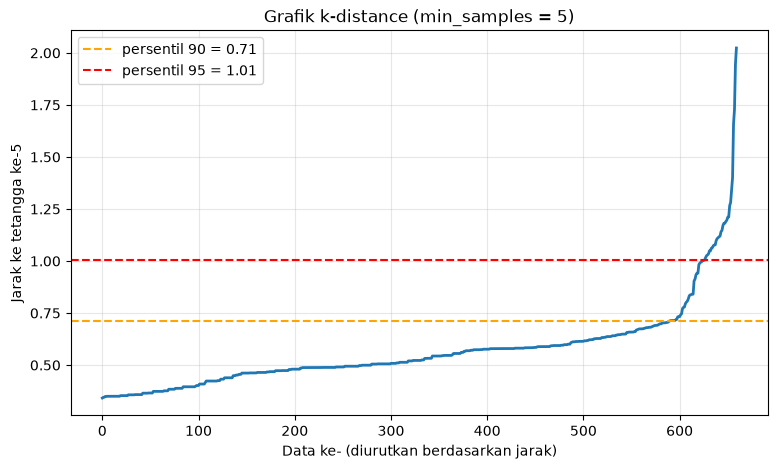

persentil 50: 0.522
persentil 75: 0.613
persentil 90: 0.714
persentil 95: 1.005
persentil 99: 1.273


In [14]:
from sklearn.neighbors import NearestNeighbors

min_samples = 5
tetangga = NearestNeighbors(n_neighbors=min_samples).fit(X_scaled)
jarak, _ = tetangga.kneighbors(X_scaled)

k_dist = np.sort(jarak[:, -1])  # jarak ke tetangga ke-min_samples, diurutkan

plt.figure(figsize=(9, 5))
plt.plot(k_dist, linewidth=2)
plt.xlabel('Data ke- (diurutkan berdasarkan jarak)')
plt.ylabel(f'Jarak ke tetangga ke-{min_samples}')
plt.title(f'Grafik k-distance (min_samples = {min_samples})')
for p, c in [(90, 'orange'), (95, 'red')]:
    plt.axhline(np.percentile(k_dist, p), color=c, linestyle='--',
                label=f'persentil {p} = {np.percentile(k_dist, p):.2f}')
plt.legend()
plt.grid(alpha=.3)
plt.show()

for p in [50, 75, 90, 95, 99]:
    print(f'persentil {p:>2}: {np.percentile(k_dist, p):.3f}')

Grafik menunjukkan **tekukan di sekitar 0,7–1,0**, dengan ekor panjang setelah persentil 95.
Nilai `eps` di sekitar **1,0** dipilih karena berada tepat di awal "ekor" tersebut — cukup besar
untuk menghubungkan titik-titik dalam satu kelompok padat, tetapi cukup kecil untuk tidak
menelan kelompok lain.

Untuk memastikan pilihan, dilakukan **uji grid** `eps` × `min_samples`:

In [15]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

hasil = []
for eps in np.arange(0.6, 1.55, 0.1):
    for ms in [3, 5, 8, 10]:
        lab = DBSCAN(eps=round(eps, 2), min_samples=ms).fit_predict(X_scaled)
        uniq = set(lab)
        n_cl = len(uniq) - (1 if -1 in uniq else 0)
        noise = (lab == -1).sum() / len(lab) * 100
        layak = n_cl > 1 and (lab != -1).sum() > n_cl
        hasil.append({
            'eps': round(eps, 2),
            'min_samples': ms,
            'cluster': n_cl,
            'noise (%)': round(noise, 1),
            'silhouette': round(silhouette_score(X_scaled, lab), 4) if layak else None,
            'DBI': round(davies_bouldin_score(X_scaled, lab), 4) if layak else None,
        })

pd.DataFrame(hasil)

,eps,min_samples,cluster,noise (%),silhouette,DBI
0,0.6,3,10,7.7,-0.0374,2.2503
1,0.6,5,8,12.4,-0.0087,2.1639
2,0.6,8,12,24.5,-0.0355,2.1895
3,0.6,10,9,42.3,-0.1167,2.3357
4,0.7,3,3,7.0,0.4348,1.9561
5,0.7,5,1,8.8,NaN,NaN
6,0.7,8,1,9.7,NaN,NaN
7,0.7,10,1,11.8,NaN,NaN
8,0.8,3,6,3.2,0.3786,1.8934
9,0.8,5,2,6.7,0.4895,2.0349


Dari tabel di atas, konfigurasi **`eps = 1.0`, `min_samples = 5`** dipilih karena:
- `min_samples = 5` mengikuti aturan praktis **minimal sebesar jumlah dimensi** (data ini punya
  5 variabel) — cukup besar untuk menolak titik acak sebagai *core point*;
- `eps = 1.0` sesuai titik tekuk grafik k-distance pada `min_samples = 5` (persentil 95 = 1,005);
- di antara seluruh nilai `eps` dengan `min_samples = 5`, `eps = 1.0` memberi **silhouette
  tertinggi (0,5212)** dengan noise masih rendah (**2,7%**);
- menghasilkan **2 cluster** yang stabil dan bermakna.

Perilaku di luar rentang itu:
- `eps` terlalu kecil (0,6) -> data pecah menjadi **8–12 cluster kecil** dengan noise 8–42%
  (*over-segmentation*), karena radius terlalu sempit untuk menyatukan titik yang sebenarnya
  sekelompok.
- `eps` terlalu besar (≥ 1,4) -> noise nyaris hilang (< 1%) tetapi **semua data menyatu** menjadi
  2 cluster raksasa (609 + 50) dan silhouette turun ke ±0,37 (*under-segmentation*) — outlier ikut
  terserap ke dalam cluster.

In [16]:
dbscan = DBSCAN(eps=1.0, min_samples=5)
df['cluster_dbscan'] = dbscan.fit_predict(X_scaled)

print('Sebaran label DBSCAN:')
print(df['cluster_dbscan'].value_counts().sort_index().to_string())

Sebaran label DBSCAN:
cluster_dbscan
-1     18
 0    608
 1     34


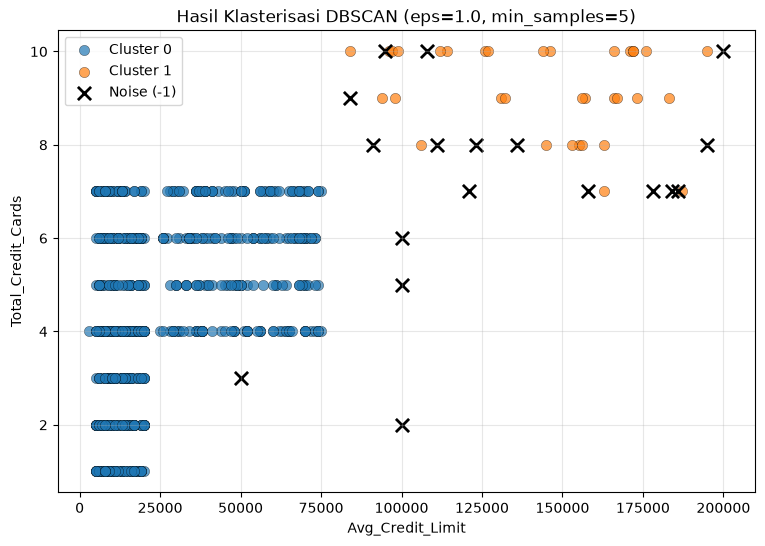

In [17]:
# Visualisasi DBSCAN (2 variabel yang paling informatif)
fig, ax = plt.subplots(figsize=(9, 6))

for c in sorted(x for x in df['cluster_dbscan'].unique() if x != -1):
    sub = df[df['cluster_dbscan'] == c]
    ax.scatter(sub['Avg_Credit_Limit'], sub['Total_Credit_Cards'],
               s=55, alpha=.7, edgecolor='k', linewidth=.3, label=f'Cluster {c}')

noise = df['cluster_dbscan'] == -1
ax.scatter(df.loc[noise, 'Avg_Credit_Limit'], df.loc[noise, 'Total_Credit_Cards'],
           c='black', marker='x', s=90, linewidth=2, label='Noise (-1)')

ax.set_xlabel('Avg_Credit_Limit')
ax.set_ylabel('Total_Credit_Cards')
ax.set_title('Hasil Klasterisasi DBSCAN (eps=1.0, min_samples=5)')
ax.legend()
ax.grid(alpha=.3)
plt.show()

In [18]:
# Profil cluster DBSCAN
profil_db = df.groupby('cluster_dbscan')[FITUR].mean().round(1)
profil_db['jumlah'] = df['cluster_dbscan'].value_counts().sort_index()
profil_db

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made,jumlah
cluster_dbscan,,,,,,
-1,128888.9,7.2,0.3,11.6,1.3,18
0,25685.9,4.4,2.6,1.9,3.8,608
1,143588.2,9.2,0.7,10.2,1.1,34


**Interpretasi hasil DBSCAN (Soal 4):**

| Label | Jumlah | Profil rata-rata |
|---|---|---|
| **0** | 608 (92,1%) | limit ±25.686, 4,4 kartu, kunjungan bank/online rendah, telepon 3,8x — **nasabah reguler** |
| **1** | 34 (5,2%) | limit ±143.588, 9,2 kartu, kunjungan online ±10,2, telepon 1,2x — **nasabah digital premium** |
| **-1 (noise)** | 18 (2,7%) | limit ±128.889 (hingga 200.000), kartu 7,2, kunjungan online **±11,6** (tertinggi) — **outlier** |

Temuan penting: DBSCAN **hanya menemukan 2 cluster**, bukan 3 seperti K-Means. Penyebabnya,
dua segmen limit rendah dan menengah **saling terhubung** dalam ruang 5 dimensi — jarak antar
keduanya tidak cukup besar untuk dianggap "celah kepadatan", sehingga DBSCAN menyatukannya
menjadi satu gugus besar. DBSCAN hanya memisahkan kelompok yang benar-benar terisolasi, yaitu
**nasabah premium** (cluster 1).

Sebaliknya, DBSCAN memberi sesuatu yang tidak bisa dilakukan K-Means: **mendeteksi 18 outlier** —
nasabah dengan limit sangat tinggi **dan** kunjungan online sangat sering tetapi hampir tidak
pernah menelepon. Nasabah seperti ini berpotensi menjadi kasus khusus (misalnya transaksi tidak
wajar) yang perlu ditinjau terpisah, bukan dipaksa masuk ke salah satu segmen.

# Soal 5 - Penentuan $k$ Terbaik dengan Elbow Method

> **Catatan:** pada soal tertulis "tentukan jumlah $k$ terbaik dengan elbow method" untuk model
> DBSCAN. Perlu dipahami bahwa **DBSCAN tidak memiliki parameter $k$** — jumlah cluster pada DBSCAN
> muncul sebagai **hasil** dari `eps` dan `min_samples`, bukan sebagai parameter masukan.
> Karena itu soal ini dijawab dari dua sisi: (a) elbow method pada K-Means dengan seluruh variabel
> sebagai pembanding, dan (b) penentuan `eps`/`min_samples` DBSCAN secara objektif.

## (a) Elbow method pada K-Means dengan seluruh variabel

Ini dilakukan agar `k` hasil K-Means dapat dibandingkan langsung dengan jumlah cluster DBSCAN,
karena keduanya memakai ruang fitur yang sama (5 variabel, sudah distandardisasi).

In [19]:
sse_all = []
K = range(1, 11)

for k in K:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    sse_all.append(model.inertia_)

tabel_all = pd.DataFrame({'k': list(K), 'SSE': np.round(sse_all, 2)})
tabel_all['penurunan SSE (%)'] = [np.nan] + [round((sse_all[i-1] - sse_all[i]) / sse_all[i-1] * 100, 2)
                                            for i in range(1, len(sse_all))]
tabel_all

,k,SSE,penurunan SSE (%)
0,1,3300.00,NaN
1,2,2040.99,38.15
2,3,933.04,54.28
3,4,780.77,16.32
4,5,704.48,9.77
5,6,642.27,8.83
6,7,599.93,6.59
7,8,567.33,5.43
8,9,542.25,4.42
9,10,516.24,4.80


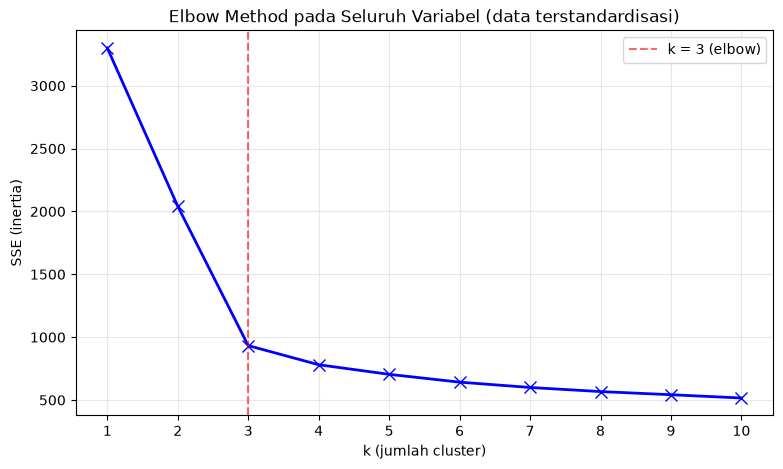

In [20]:
plt.figure(figsize=(9, 5))
plt.plot(list(K), sse_all, 'bx-', linewidth=2, markersize=8)
plt.xlabel('k (jumlah cluster)')
plt.ylabel('SSE (inertia)')
plt.title('Elbow Method pada Seluruh Variabel (data terstandardisasi)')
plt.xticks(list(K))
plt.axvline(x=3, color='red', linestyle='--', alpha=.6, label='k = 3 (elbow)')
plt.legend()
plt.grid(alpha=.3)
plt.show()

In [21]:
# Bandingkan silhouette tiap k sebagai cross-check
from sklearn.metrics import silhouette_score

banding = []
for k in range(2, 8):
    lab = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X_scaled)
    banding.append({'k': k,
                    'silhouette': round(silhouette_score(X_scaled, lab), 4),
                    'DBI': round(davies_bouldin_score(X_scaled, lab), 4)})
pd.DataFrame(banding)

,k,silhouette,DBI
0,2,0.4184,0.9300
1,3,0.5157,0.6797
2,4,0.3557,1.1182
3,5,0.2717,1.3298
4,6,0.2560,1.3470
5,7,0.2482,1.4331


**Analisis elbow (a):** SSE turun dari 3.300 (k=1) menjadi 2.041 (k=2), lalu **933 (k=3)** —
penurunan paling tajam terjadi hingga `k=3`. Setelah itu penurunan makin kecil
(780 → 704 → 642 → ...) dan grafik mendatar. Jadi **$k = 3$** adalah elbow-nya.
Silhouette juga **tertinggi pada $k = 3$** (±0,516) dan DBI **terendah** pada `k=3` (±0,68) —
ketiga metrik sepakat bahwa struktur data memang terdiri dari **3 segmen**.

## (b) Penentuan parameter DBSCAN secara objektif

DBSCAN tidak punya `k`, sehingga yang ditentukan adalah:

| Parameter | Nilai | Dasar penentuan |
|---|---|---|
| `min_samples` | 5 | aturan praktis: minimal sebesar jumlah dimensi (5 variabel), cukup untuk menghindari cluster palsu dari titik acak |
| `eps` | 1,0 | titik tekuk (*knee*) grafik k-distance pada `min_samples=5`, di sekitar persentil 95 (±1,02); dikonfirmasi uji grid — memberi noise terendah dengan silhouette tertinggi |

**Mengapa hasilnya 2 cluster, bukan 3?** Karena DBSCAN mendefinisikan cluster dari
**keterhubungan kepadatan**, bukan dari jarak ke centroid. Dua segmen limit rendah dan menengah
masih tersambung oleh titik-titik perantara dalam ruang 5 dimensi, sehingga DBSCAN melihatnya
sebagai satu gugus padat. Ini bukan kesalahan parameter, melainkan **perbedaan asumsi** antara
kedua algoritma — dan justru inilah pelajaran utamanya: K-Means memaksa semua data masuk ke `k`
kelompok, sedangkan DBSCAN mengikuti struktur kepadatan data apa adanya.

# Soal 6 - Silhouette Score dan Davies-Bouldin Index Model DBSCAN

In [22]:
lab_db = df['cluster_dbscan'].values
mask = lab_db != -1

sil_semua = silhouette_score(X_scaled, lab_db)
dbi_semua = davies_bouldin_score(X_scaled, lab_db)

sil_bersih = silhouette_score(X_scaled[mask], lab_db[mask])
dbi_bersih = davies_bouldin_score(X_scaled[mask], lab_db[mask])

hasil_eval = pd.DataFrame([
    {'skenario': 'Semua data (noise ikut dihitung)', 'n': len(lab_db),
     'silhouette': round(sil_semua, 4), 'DBI': round(dbi_semua, 4)},
    {'skenario': 'Tanpa noise (hanya anggota cluster)', 'n': int(mask.sum()),
     'silhouette': round(sil_bersih, 4), 'DBI': round(dbi_bersih, 4)},
])
hasil_eval

,skenario,n,silhouette,DBI
0,Semua data (noise ikut dihitung),660,0.5212,2.1613
1,Tanpa noise (hanya anggota cluster),642,0.5680,0.6015


In [23]:
print(f'Jumlah cluster : {len(set(lab_db)) - 1}')
print(f'Jumlah noise   : {int((~mask).sum())} data ({(~mask).mean()*100:.2f}%)')
print()
print(f'Silhouette score (semua data) : {sil_semua:.4f}')
print(f'Silhouette score (tanpa noise): {sil_bersih:.4f}')
print(f'Davies-Bouldin Index (semua data) : {dbi_semua:.4f}')
print(f'Davies-Bouldin Index (tanpa noise): {dbi_bersih:.4f}')

Jumlah cluster : 2
Jumlah noise   : 18 data (2.73%)

Silhouette score (semua data) : 0.5212
Silhouette score (tanpa noise): 0.5680
Davies-Bouldin Index (semua data) : 2.1613
Davies-Bouldin Index (tanpa noise): 0.6015


**Jawaban Soal 6:**

| Metrik | Semua data | Tanpa noise | Interpretasi |
|---|---|---|---|
| **Silhouette score** | **0,5212** | **0,5680** | sedang–baik (skala -1 s/d 1, makin mendekati 1 makin baik) |
| **Davies-Bouldin Index** | **2,1613** | **0,6015** | makin kecil makin baik (0 = ideal) |

**Penjelasan:**
1. Nilai resmi silhouette untuk model DBSCAN adalah **0,5212** (dihitung pada seluruh 660 data,
   termasuk noise, karena itulah keluaran `silhouette_score(X_scaled, labels)`).
   Jika noise dikeluarkan — praktik yang lebih tepat karena titik noise memang bukan anggota
   cluster mana pun — nilainya naik menjadi **0,5680**.
2. DBI **2,1613** (semua data) terlihat buruk, tetapi angka ini **terdistorsi oleh noise**:
   sklearn memperlakukan label `-1` sebagai satu "cluster" tambahan yang tersebar di mana-mana,
   sehingga separasinya dinilai sangat buruk. Setelah noise dikeluarkan, DBI turun drastis menjadi
   **0,6015** — nilai yang **sangat baik** (mendekati 0), menandakan kedua cluster DBSCAN
   terpisah dengan rapi.
3. Perbandingan dengan K-Means (`k=3`, seluruh variabel): silhouette **0,5157** dan DBI **0,6797**.
   DBSCAN unggul tipis setelah noise dibuang (0,5680 vs 0,5157; DBI 0,6015 vs 0,6797),
   tetapi DBSCAN hanya menghasilkan 2 cluster sehingga tidak dapat memisahkan segmen
   rendah dan menengah.

# Kesimpulan Tugas

## Ringkasan jawaban

| Soal | Jawaban |
|---|---|
| 1 | Sebaran **tidak linier** — titik menggerombol pada 10 kolom `Total_Credit_Cards`, membentuk 3 tingkat limit dengan celah di ±20–25 ribu dan ±75–84 ribu; korelasi hanya ±0,61 |
| 2 | Elbow method pada `Avg_Credit_Limit` + `Total_Credit_Cards` → **$k = 3$** (penurunan SSE terbesar pada 2→3, ±70%, lalu melandai) |
| 3 | 3 segmen: **rendah** (431 nasabah, limit ±13,8 rb, 3,9 kartu), **menengah** (190 nasabah, limit ±57 rb, 5,7 kartu), **premium** (39 nasabah, limit ±154 rb, 8,7 kartu) |
| 4 | DBSCAN (`eps=1.0`, `min_samples=5`, 5 variabel terstandardisasi) → **2 cluster + 18 noise (2,7%)** |
| 5 | Elbow seluruh variabel → **$k = 3$** (silhouette tertinggi 0,516, DBI terendah 0,680); untuk DBSCAN, `eps` ditentukan dari grafik k-distance + uji grid → **1,0** |
| 6 | **Silhouette = 0,5212** (0,5680 tanpa noise) dan **DBI = 2,1613** (0,6015 tanpa noise) |

## Perbandingan K-Means vs DBSCAN pada data ini

| Aspek | K-Means | DBSCAN |
|---|---|---|
| Parameter | `k = 3` (ditentukan) | `eps = 1.0`, `min_samples = 5` |
| Jumlah cluster | 3 | 2 |
| Noise / outlier | tidak ada (semua data dipaksa masuk cluster) | **18 nasabah terdeteksi sebagai outlier** |
| Silhouette | 0,5157 | 0,5212 (0,5680 tanpa noise) |
| DBI | 0,6797 | 2,1613 (0,6015 tanpa noise) |
| Kelebihan di kasus ini | memisahkan **3 segmen** limit secara rapi dan dapat diinterpretasikan | menemukan **outlier** dan kelompok premium yang benar-benar terisolasi |

**Kesimpulan akhir:**
1. Untuk **segmentasi nasabah** (tujuan: membagi pasar menjadi 3 kelompok untuk strategi promosi),
   **K-Means `k=3` lebih tepat**, karena segmen rendah–menengah–premium memang ada dan
   DBSCAN menyatukan dua segmen terbawah.
2. Untuk **deteksi anomali / nasabah tidak wajar**, **DBSCAN lebih tepat**, karena hanya DBSCAN
   yang mampu menandai 18 nasabah sebagai noise.
3. Kedua algoritma **tidak saling menggantikan**: K-Means memaksa semua data masuk ke `k` kelompok,
   sedangkan DBSCAN mengikuti kepadatan data dan membiarkan data aneh tetap sebagai noise.
4. Seluruh variabel **wajib distandardisasi** sebelum DBSCAN, karena DBSCAN berbasis jarak dan
   `Avg_Credit_Limit` memiliki rentang jauh lebih besar daripada variabel hitungan lainnya.